In [1]:
# Data manipulation
import pandas as pd
import numpy as np

# Data visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Data preprocessing
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

# Machine learning algorithms
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier

# Model evaluation
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_auc_score,
    RocCurveDisplay
)

# Utilities
import warnings
warnings.filterwarnings('ignore')

# Visualization settings
sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)

print("All libraries imported successfully!")

All libraries imported successfully!


In [5]:
# Load the Bank Marketing Dataset

file_path = "bank-additional-full.csv"

df = pd.read_csv(
    file_path,
    sep=";"
)

print("Dataset loaded successfully!")

Dataset loaded successfully!


In [7]:
print("Dataset Shape:", df.shape)

print("\nFirst 5 Records:")
display(df.head())

Dataset Shape: (41188, 21)

First 5 Records:


,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,37,services,married,high.school,no,yes,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,56,services,married,high.school,no,no,yes,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no


In [9]:
print("Dataset Columns:\n")

print(df.columns.tolist())

Dataset Columns:

['age', 'job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'day_of_week', 'duration', 'campaign', 'pdays', 'previous', 'poutcome', 'emp.var.rate', 'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed', 'y']


In [11]:
print("Dataset Information:\n")

df.info()

Dataset Information:

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 41188 entries, 0 to 41187
Data columns (total 21 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   age             41188 non-null  int64  
 1   job             41188 non-null  object 
 2   marital         41188 non-null  object 
 3   education       41188 non-null  object 
 4   default         41188 non-null  object 
 5   housing         41188 non-null  object 
 6   loan            41188 non-null  object 
 7   contact         41188 non-null  object 
 8   month           41188 non-null  object 
 9   day_of_week     41188 non-null  object 
 10  duration        41188 non-null  int64  
 11  campaign        41188 non-null  int64  
 12  pdays           41188 non-null  int64  
 13  previous        41188 non-null  int64  
 14  poutcome        41188 non-null  object 
 15  emp.var.rate    41188 non-null  float64
 16  cons.price.idx  41188 non-null  float64
 17  cons.conf

In [13]:
print("Missing Values:\n")

print(df.isnull().sum())

Missing Values:

age               0
job               0
marital           0
education         0
default           0
housing           0
loan              0
contact           0
month             0
day_of_week       0
duration          0
campaign          0
pdays             0
previous          0
poutcome          0
emp.var.rate      0
cons.price.idx    0
cons.conf.idx     0
euribor3m         0
nr.employed       0
y                 0
dtype: int64


In [15]:
print("Number of Duplicate Records:")

print(df.duplicated().sum())

Number of Duplicate Records:
12


In [17]:
print("Statistical Summary:\n")

display(df.describe(include="all").T)

Statistical Summary:



,count,unique,top,freq,mean,std,min,25%,50%,75%,max
age,41188.0,NaN,NaN,NaN,40.02406,10.42125,17.0,32.0,38.0,47.0,98.0
job,41188,12,admin.,10422,NaN,NaN,NaN,NaN,NaN,NaN,NaN
marital,41188,4,married,24928,NaN,NaN,NaN,NaN,NaN,NaN,NaN
education,41188,8,university.degree,12168,NaN,NaN,NaN,NaN,NaN,NaN,NaN
default,41188,3,no,32588,NaN,NaN,NaN,NaN,NaN,NaN,NaN
housing,41188,3,yes,21576,NaN,NaN,NaN,NaN,NaN,NaN,NaN
loan,41188,3,no,33950,NaN,NaN,NaN,NaN,NaN,NaN,NaN
contact,41188,2,cellular,26144,NaN,NaN,NaN,NaN,NaN,NaN,NaN
month,41188,10,may,13769,NaN,NaN,NaN,NaN,NaN,NaN,NaN
day_of_week,41188,5,thu,8623,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [19]:
# Target variable distribution

print("Subscription Distribution:\n")

print(df['y'].value_counts())

Subscription Distribution:

y
no     36548
yes     4640
Name: count, dtype: int64


In [21]:
# Calculate target percentages

target_percentage = df['y'].value_counts(normalize=True) * 100

print("Subscription Percentage:\n")

print(target_percentage.round(2))

Subscription Percentage:

y
no     88.73
yes    11.27
Name: proportion, dtype: float64


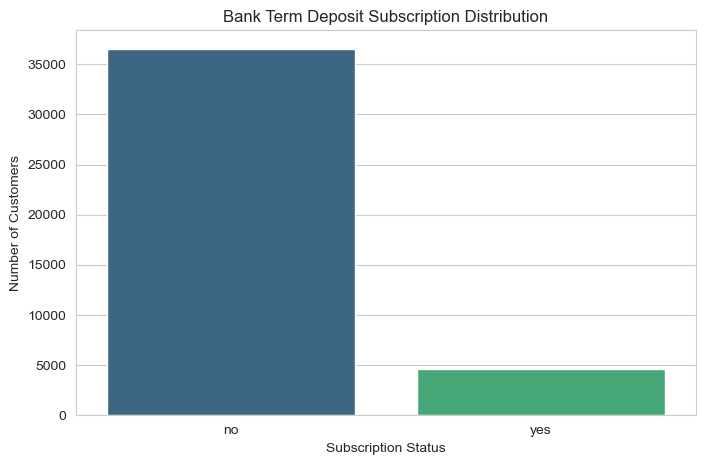

In [23]:
# Visualize target variable

plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x='y',
    hue='y',
    palette='viridis',
    legend=False
)

plt.title('Bank Term Deposit Subscription Distribution')
plt.xlabel('Subscription Status')
plt.ylabel('Number of Customers')

plt.show()

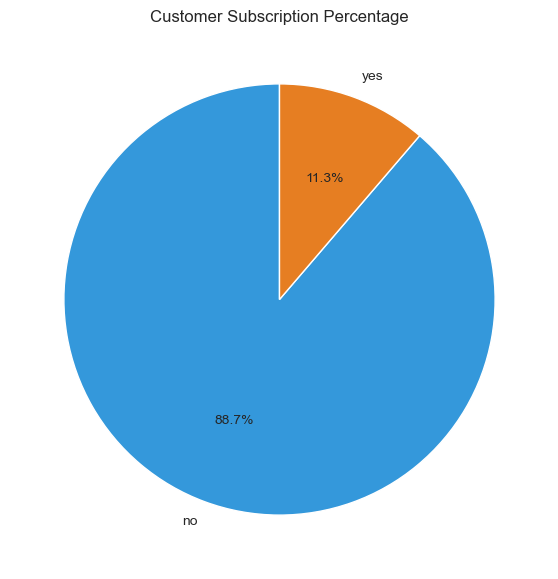

In [25]:
# Subscription distribution pie chart

plt.figure(figsize=(7, 7))

df['y'].value_counts().plot(
    kind='pie',
    autopct='%1.1f%%',
    colors=['#3498DB', '#E67E22'],
    startangle=90
)

plt.title('Customer Subscription Percentage')
plt.ylabel('')

plt.show()

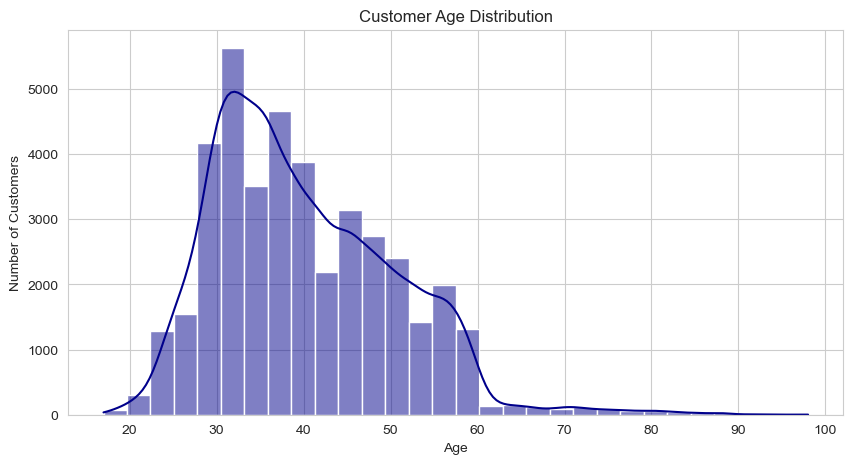

In [29]:
# Customer Age Distribution

plt.figure(figsize=(10, 5))

sns.histplot(
    df['age'],
    bins=30,
    kde=True,
    color='darkblue'
)

plt.title('Customer Age Distribution')
plt.xlabel('Age')
plt.ylabel('Number of Customers')

plt.show()

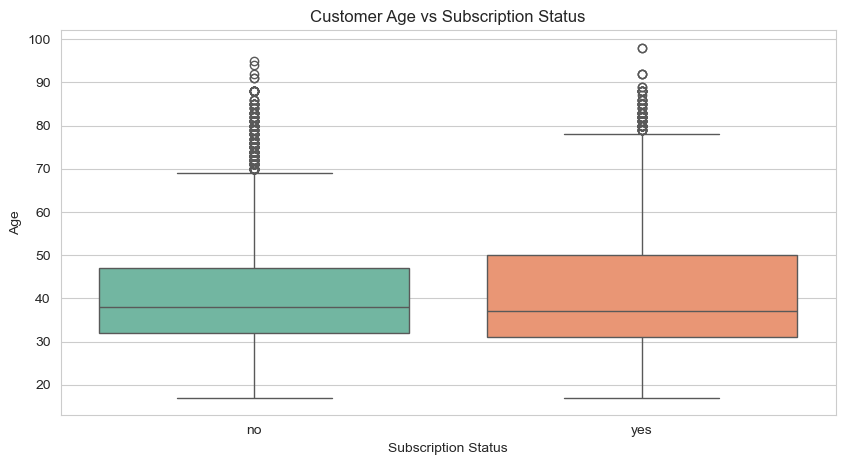

In [31]:
plt.figure(figsize=(10, 5))

sns.boxplot(
    data=df,
    x='y',
    y='age',
    hue='y',
    palette='Set2',
    legend=False
)

plt.title('Customer Age vs Subscription Status')
plt.xlabel('Subscription Status')
plt.ylabel('Age')

plt.show()

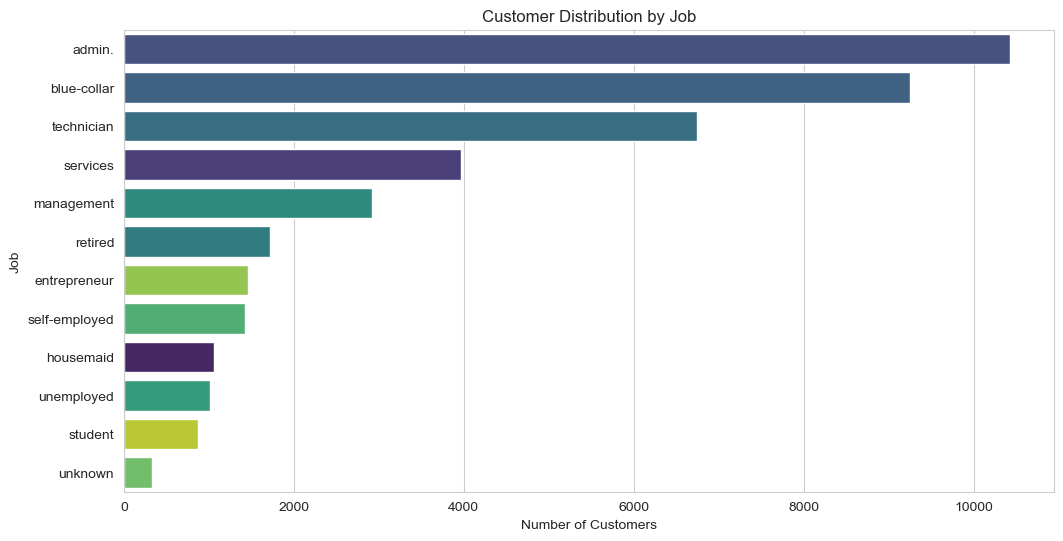

In [33]:
plt.figure(figsize=(12, 6))

sns.countplot(
    data=df,
    y='job',
    hue='job',
    order=df['job'].value_counts().index,
    palette='viridis',
    legend=False
)

plt.title('Customer Distribution by Job')
plt.xlabel('Number of Customers')
plt.ylabel('Job')

plt.show()

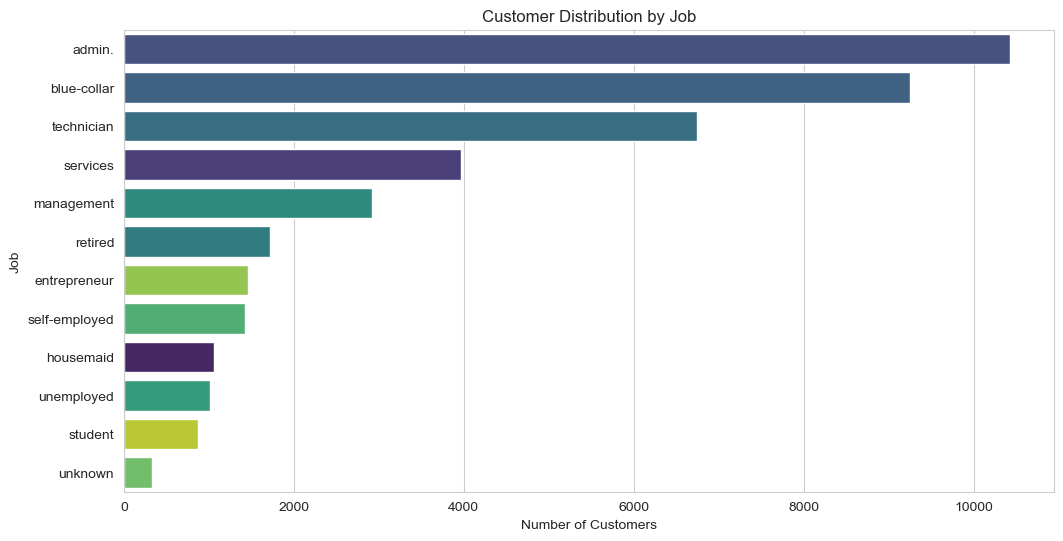

In [35]:
plt.figure(figsize=(12, 6))

sns.countplot(
    data=df,
    y='job',
    hue='job',
    order=df['job'].value_counts().index,
    palette='viridis',
    legend=False
)

plt.title('Customer Distribution by Job')
plt.xlabel('Number of Customers')
plt.ylabel('Job')

plt.show()

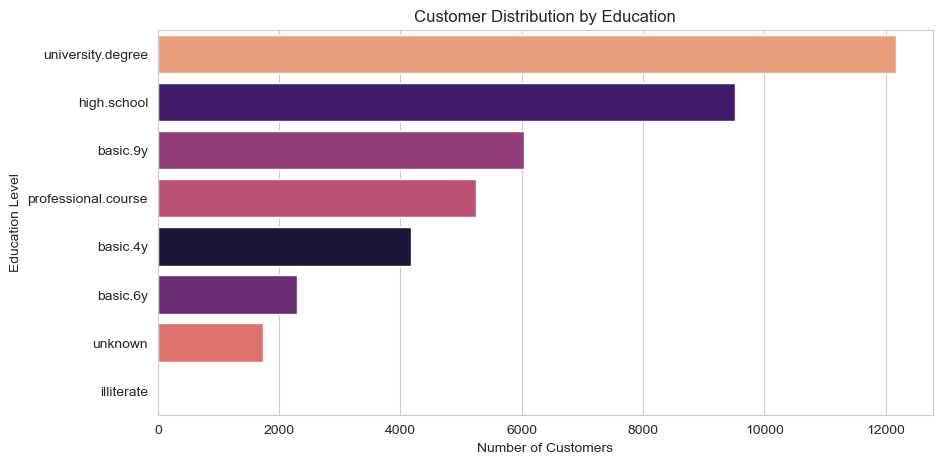

In [37]:
plt.figure(figsize=(10, 5))

sns.countplot(
    data=df,
    y='education',
    hue='education',
    order=df['education'].value_counts().index,
    palette='magma',
    legend=False
)

plt.title('Customer Distribution by Education')
plt.xlabel('Number of Customers')
plt.ylabel('Education Level')

plt.show()

y,no,yes
job,,
student,68.57,31.43
retired,74.77,25.23
unemployed,85.80,14.20
admin.,87.03,12.97
management,88.78,11.22
unknown,88.79,11.21
technician,89.17,10.83
self-employed,89.51,10.49
housemaid,90.00,10.00


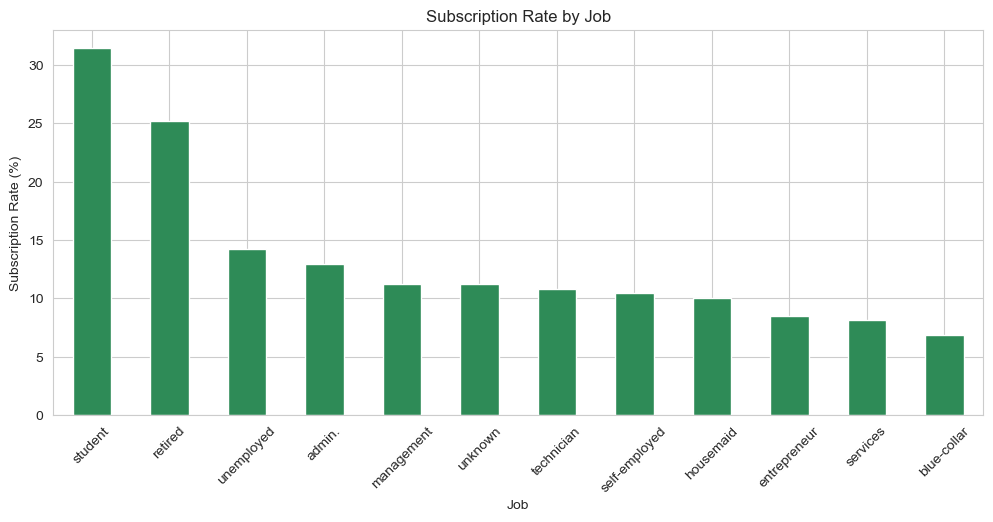

In [39]:
job_subscription = pd.crosstab(
    df['job'],
    df['y'],
    normalize='index'
) * 100

job_subscription = job_subscription.sort_values(
    by='yes',
    ascending=False
)

display(job_subscription.round(2))

job_subscription['yes'].plot(
    kind='bar',
    figsize=(12, 5),
    color='seagreen'
)

plt.title('Subscription Rate by Job')
plt.xlabel('Job')
plt.ylabel('Subscription Rate (%)')
plt.xticks(rotation=45)

plt.show()

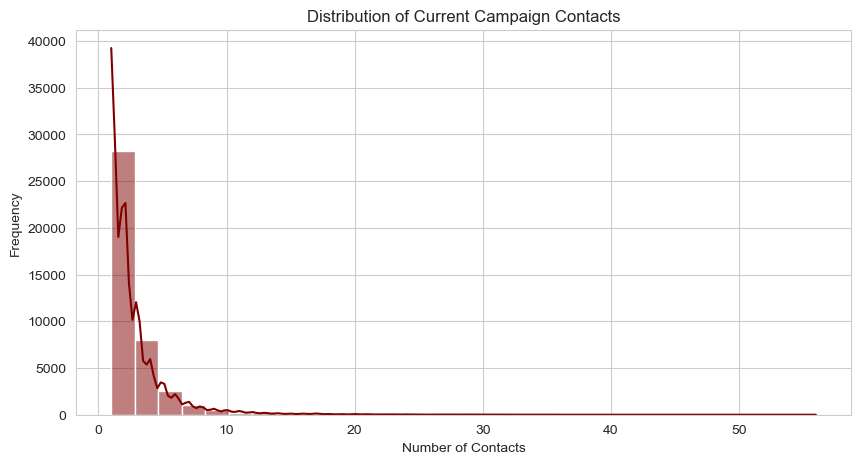

In [43]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data=df,
    x='campaign',
    bins=30,
    kde=True,
    color='maroon'
)

plt.title('Distribution of Current Campaign Contacts')
plt.xlabel('Number of Contacts')
plt.ylabel('Frequency')

plt.show()

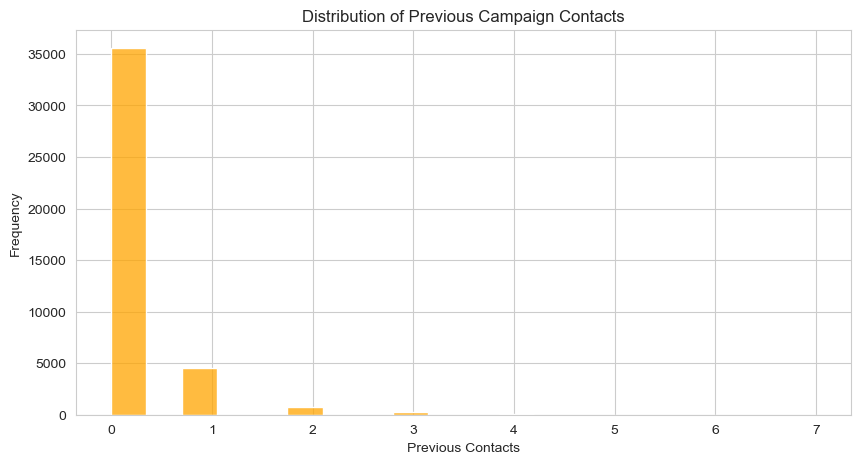

In [45]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data=df,
    x='previous',
    bins=20,
    color='orange'
)

plt.title('Distribution of Previous Campaign Contacts')
plt.xlabel('Previous Contacts')
plt.ylabel('Frequency')

plt.show()

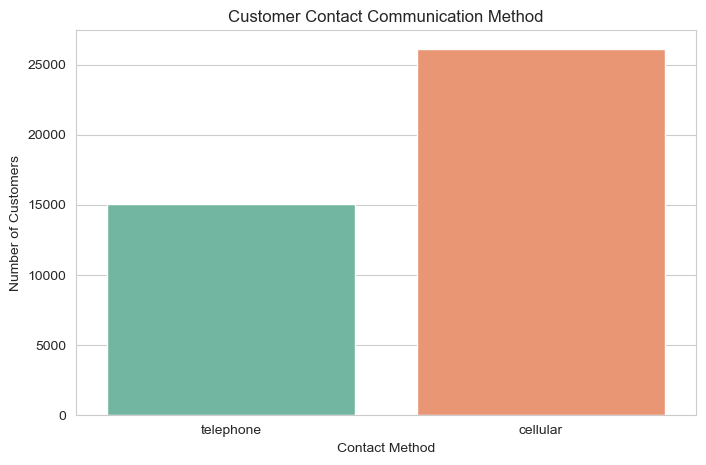

In [47]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x='contact',
    hue='contact',
    palette='Set2',
    legend=False
)

plt.title('Customer Contact Communication Method')
plt.xlabel('Contact Method')
plt.ylabel('Number of Customers')

plt.show()

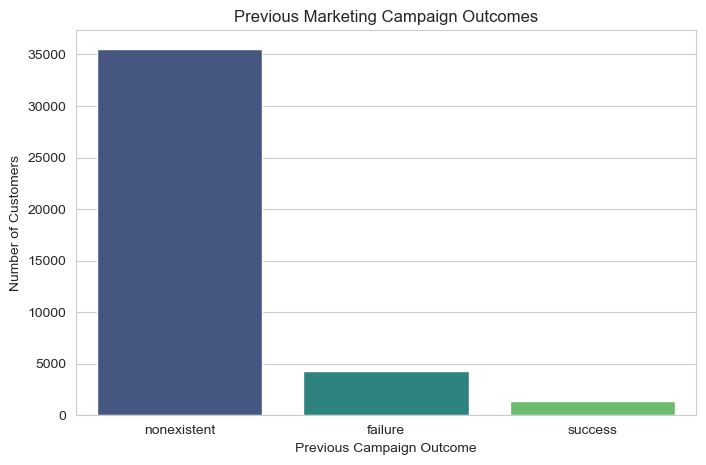

In [49]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x='poutcome',
    hue='poutcome',
    palette='viridis',
    legend=False
)

plt.title('Previous Marketing Campaign Outcomes')
plt.xlabel('Previous Campaign Outcome')
plt.ylabel('Number of Customers')

plt.show()

y,no,yes
poutcome,,
failure,85.77,14.23
nonexistent,91.17,8.83
success,34.89,65.11


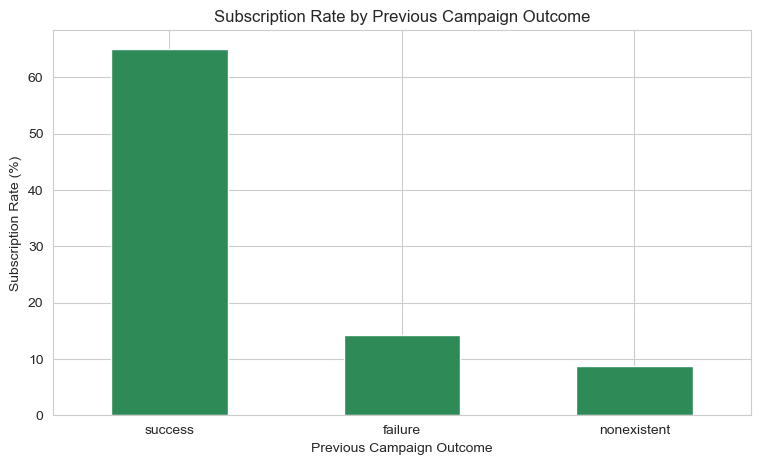

In [51]:
campaign_outcome = pd.crosstab(
    df['poutcome'],
    df['y'],
    normalize='index'
) * 100

display(campaign_outcome.round(2))

campaign_outcome['yes'].sort_values(
    ascending=False
).plot(
    kind='bar',
    figsize=(9, 5),
    color='seagreen'
)

plt.title('Subscription Rate by Previous Campaign Outcome')
plt.xlabel('Previous Campaign Outcome')
plt.ylabel('Subscription Rate (%)')
plt.xticks(rotation=0)

plt.show()

y,no,yes
contact,,
cellular,85.26,14.74
telephone,94.77,5.23


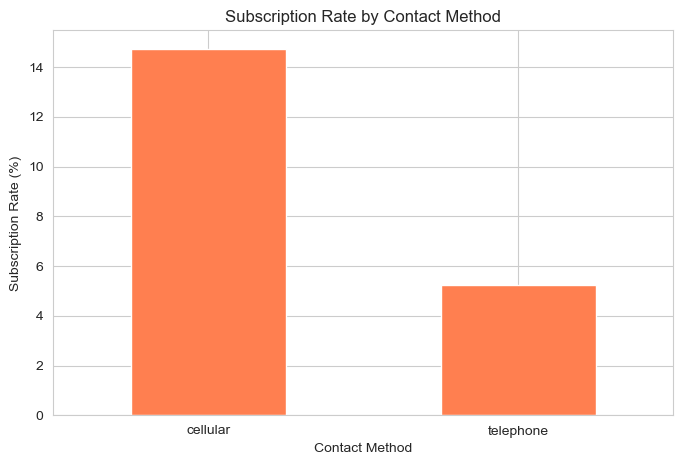

In [53]:
contact_subscription = pd.crosstab(
    df['contact'],
    df['y'],
    normalize='index'
) * 100

display(contact_subscription.round(2))

contact_subscription['yes'].plot(
    kind='bar',
    figsize=(8, 5),
    color='coral'
)

plt.title('Subscription Rate by Contact Method')
plt.xlabel('Contact Method')
plt.ylabel('Subscription Rate (%)')
plt.xticks(rotation=0)

plt.show()

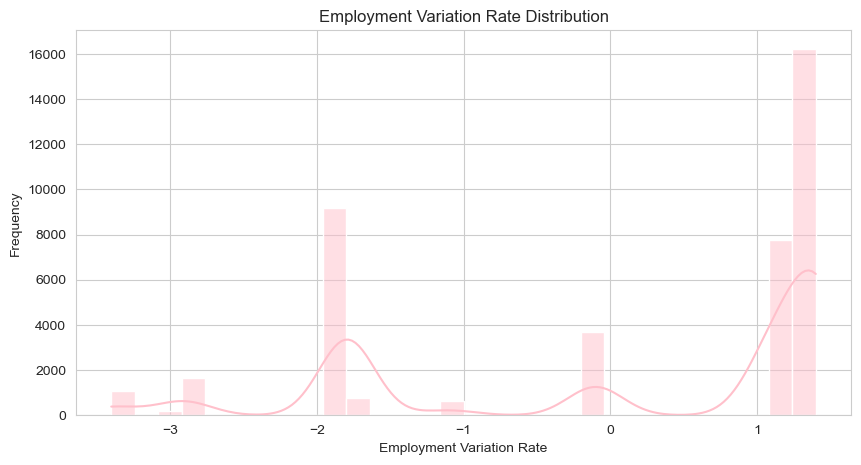

In [55]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data=df,
    x='emp.var.rate',
    bins=30,
    kde=True,
    color='pink'
)

plt.title('Employment Variation Rate Distribution')
plt.xlabel('Employment Variation Rate')
plt.ylabel('Frequency')

plt.show()

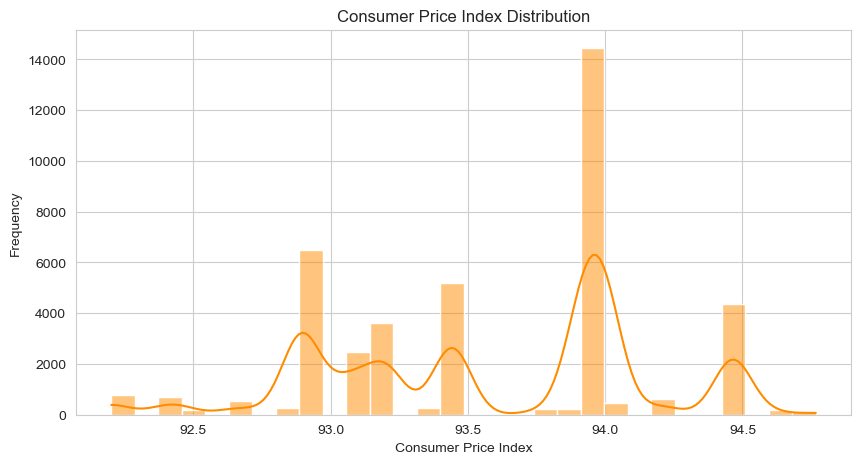

In [59]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data=df,
    x='cons.price.idx',
    bins=30,
    kde=True,
    color='darkorange'
)

plt.title('Consumer Price Index Distribution')
plt.xlabel('Consumer Price Index')
plt.ylabel('Frequency')

plt.show()

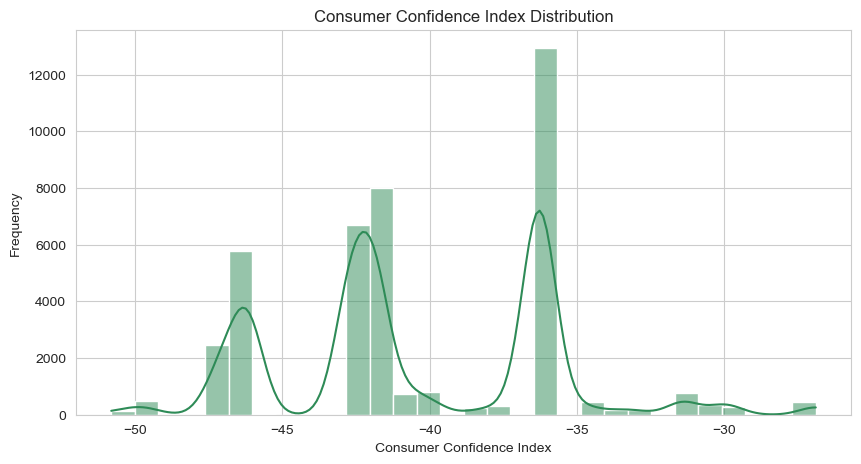

In [61]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data=df,
    x='cons.conf.idx',
    bins=30,
    kde=True,
    color='seagreen'
)

plt.title('Consumer Confidence Index Distribution')
plt.xlabel('Consumer Confidence Index')
plt.ylabel('Frequency')

plt.show()

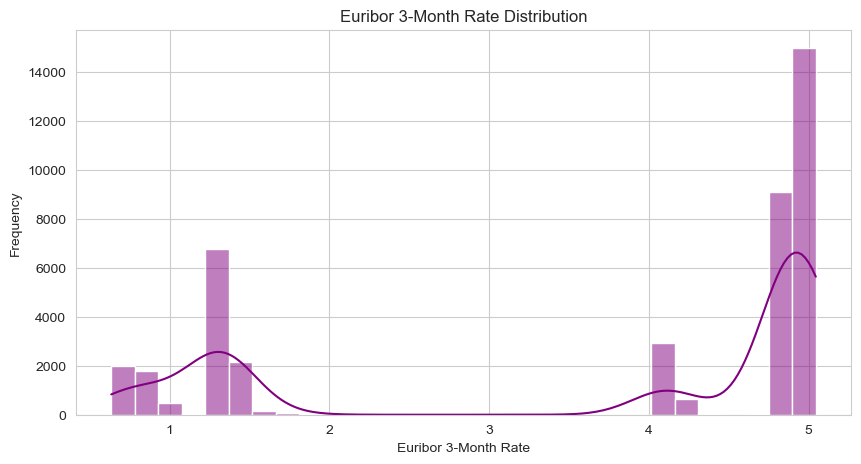

In [63]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data=df,
    x='euribor3m',
    bins=30,
    kde=True,
    color='purple'
)

plt.title('Euribor 3-Month Rate Distribution')
plt.xlabel('Euribor 3-Month Rate')
plt.ylabel('Frequency')

plt.show()

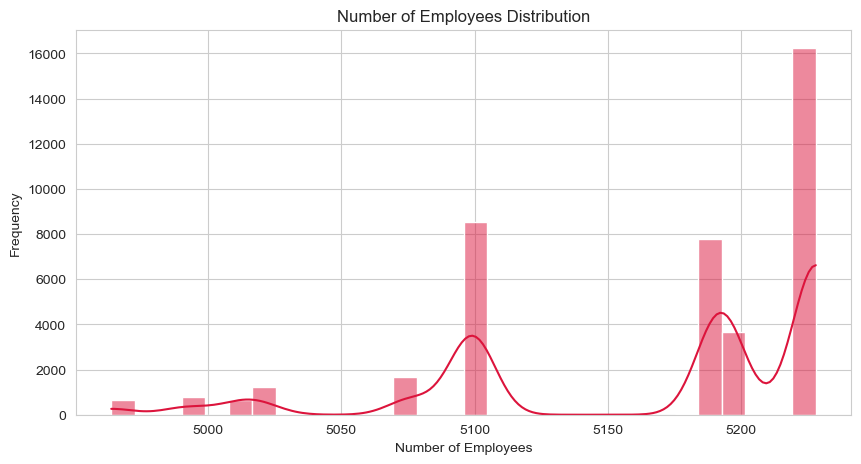

In [65]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data=df,
    x='nr.employed',
    bins=30,
    kde=True,
    color='crimson'
)

plt.title('Number of Employees Distribution')
plt.xlabel('Number of Employees')
plt.ylabel('Frequency')

plt.show()

In [67]:
economic_columns = [
    'emp.var.rate',
    'cons.price.idx',
    'cons.conf.idx',
    'euribor3m',
    'nr.employed'
]

economic_analysis = df.groupby('y')[economic_columns].mean().T

display(economic_analysis.round(3))

y,no,yes
emp.var.rate,0.249,-1.233
cons.price.idx,93.604,93.354
cons.conf.idx,-40.593,-39.790
euribor3m,3.811,2.123
nr.employed,5176.167,5095.116


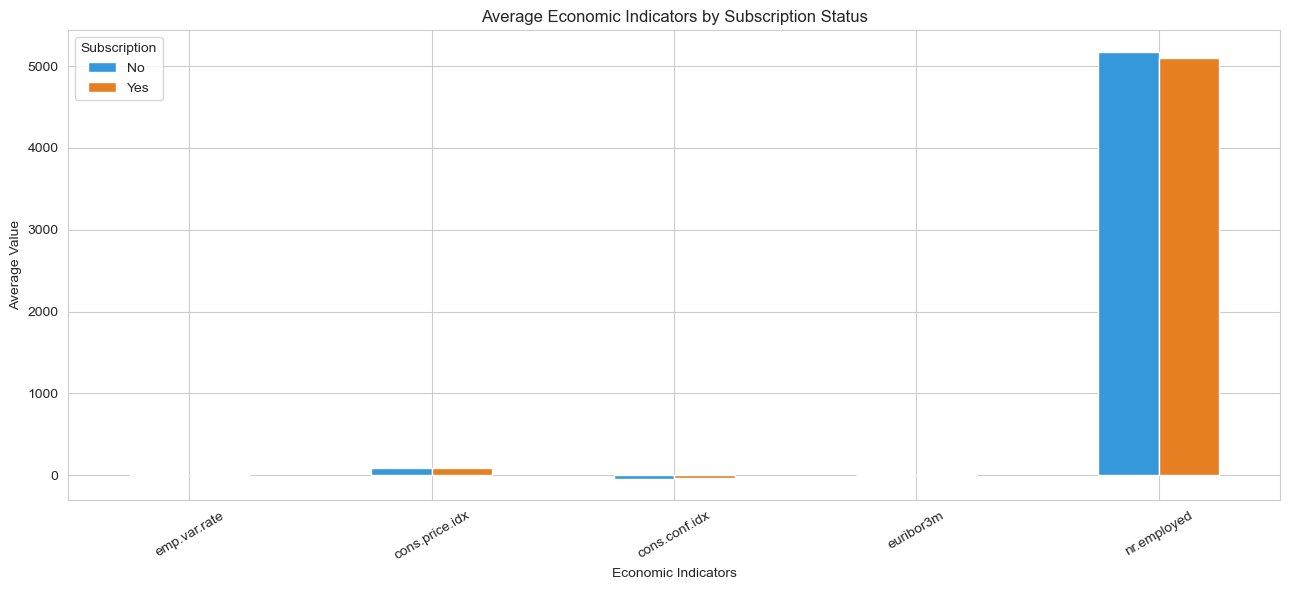

In [69]:
economic_analysis.plot(
    kind='bar',
    figsize=(13, 6),
    color=['#3498DB', '#E67E22']
)

plt.title('Average Economic Indicators by Subscription Status')
plt.xlabel('Economic Indicators')
plt.ylabel('Average Value')
plt.xticks(rotation=30)
plt.legend(title='Subscription', labels=['No', 'Yes'])

plt.tight_layout()
plt.show()

In [71]:
# Select numerical columns
numeric_df = df.select_dtypes(include=np.number).copy()

# Convert target variable into numerical format
numeric_df['target_encoded'] = df['y'].map({
    'no': 0,
    'yes': 1
})

# Calculate correlation
correlation_matrix = numeric_df.corr()

# Display correlation with target
target_correlation = correlation_matrix['target_encoded'].sort_values(
    ascending=False
)

print("Correlation with Subscription Target:")
display(target_correlation)

Correlation with Subscription Target:


target_encoded    1.000000
duration          0.405274
previous          0.230181
cons.conf.idx     0.054878
age               0.030399
campaign         -0.066357
cons.price.idx   -0.136211
emp.var.rate     -0.298334
euribor3m        -0.307771
pdays            -0.324914
nr.employed      -0.354678
Name: target_encoded, dtype: float64

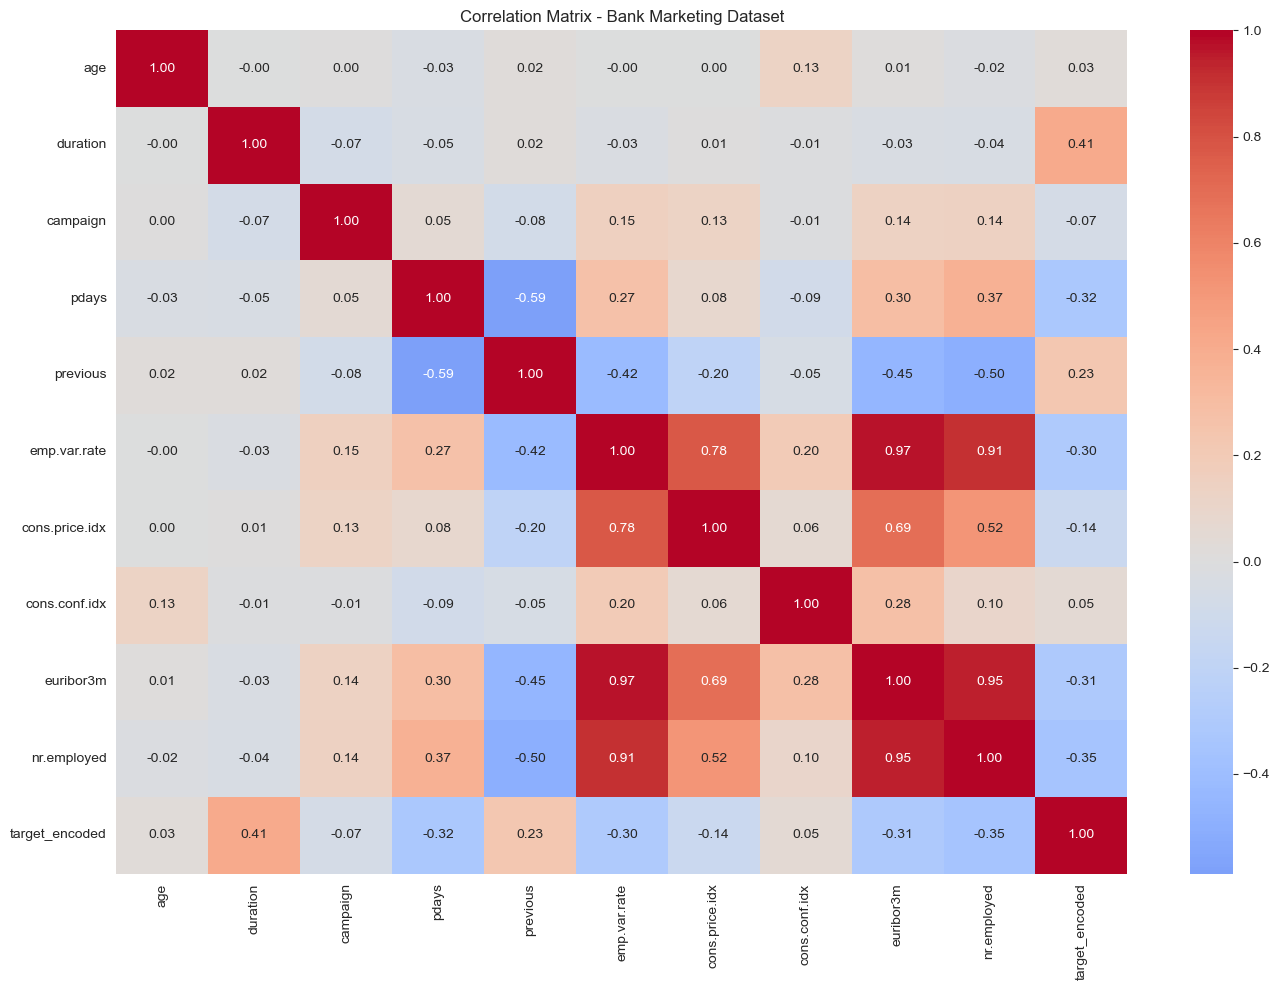

Duration column removed successfully!
Dataset shape: (41188, 20)


In [77]:
plt.figure(figsize=(14, 10))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    center=0
)

plt.title('Correlation Matrix - Bank Marketing Dataset')
plt.tight_layout()
plt.show()# Create a copy of the dataset
df_model = df.copy()

# Remove duration to prevent data leakage
df_model.drop(columns=['duration'], inplace=True)

print("Duration column removed successfully!")
print("Dataset shape:", df_model.shape)

In [79]:
# Create a copy of the dataset
df_model = df.copy()

# Remove duration to prevent data leakage
df_model.drop(columns=['duration'], inplace=True)

print("Duration column removed successfully!")
print("Dataset shape:", df_model.shape)

Duration column removed successfully!
Dataset shape: (41188, 20)


In [81]:
# Input features
X = df_model.drop('y', axis=1)

# Target variable
y = df_model['y'].map({
    'no': 0,
    'yes': 1
})

print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (41188, 19)
Target shape: (41188,)


In [83]:
# Identify numerical columns
numerical_features = X.select_dtypes(
    include=np.number
).columns.tolist()

# Identify categorical columns
categorical_features = X.select_dtypes(
    exclude=np.number
).columns.tolist()

print("Numerical Features:")
print(numerical_features)

print("\nCategorical Features:")
print(categorical_features)

print("\nNumber of Numerical Features:", len(numerical_features))
print("Number of Categorical Features:", len(categorical_features))

Numerical Features:
['age', 'campaign', 'pdays', 'previous', 'emp.var.rate', 'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed']

Categorical Features:
['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'day_of_week', 'poutcome']

Number of Numerical Features: 9
Number of Categorical Features: 10


In [85]:
print("Missing Values:")
print(X.isnull().sum().sum())

print("\nUnknown Values in Categorical Columns:")

for col in categorical_features:
    unknown_count = (X[col] == 'unknown').sum()
    if unknown_count > 0:
        print(f"{col}: {unknown_count}")

Missing Values:
0

Unknown Values in Categorical Columns:
job: 330
marital: 80
education: 1731
default: 8597
housing: 990
loan: 990


In [87]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training Features:", X_train.shape)
print("Testing Features:", X_test.shape)

print("\nTraining Target Distribution:")
print(y_train.value_counts(normalize=True) * 100)

print("\nTesting Target Distribution:")
print(y_test.value_counts(normalize=True) * 100)

Training Features: (32950, 19)
Testing Features: (8238, 19)

Training Target Distribution:
y
0    88.734446
1    11.265554
Name: proportion, dtype: float64

Testing Target Distribution:
y
0    88.73513
1    11.26487
Name: proportion, dtype: float64


In [89]:
# Numerical preprocessing
numeric_transformer = StandardScaler()

# Categorical preprocessing
categorical_transformer = OneHotEncoder(
    handle_unknown='ignore'
)

# Combine preprocessing steps
preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, numerical_features),
        ('cat', categorical_transformer, categorical_features)
    ]
)

print("Preprocessing pipeline created successfully!")

Preprocessing pipeline created successfully!


In [91]:
# Fit only on training data
X_train_processed = preprocessor.fit_transform(X_train)

# Transform test data using the fitted preprocessor
X_test_processed = preprocessor.transform(X_test)

print("Preprocessing completed!")

print("Processed Training Shape:", X_train_processed.shape)
print("Processed Testing Shape:", X_test_processed.shape)

Preprocessing completed!
Processed Training Shape: (32950, 62)
Processed Testing Shape: (8238, 62)


Training Target Distribution:
y
0    29238
1     3712
Name: count, dtype: int64

Percentage Distribution:
y
0    88.734446
1    11.265554
Name: proportion, dtype: float64


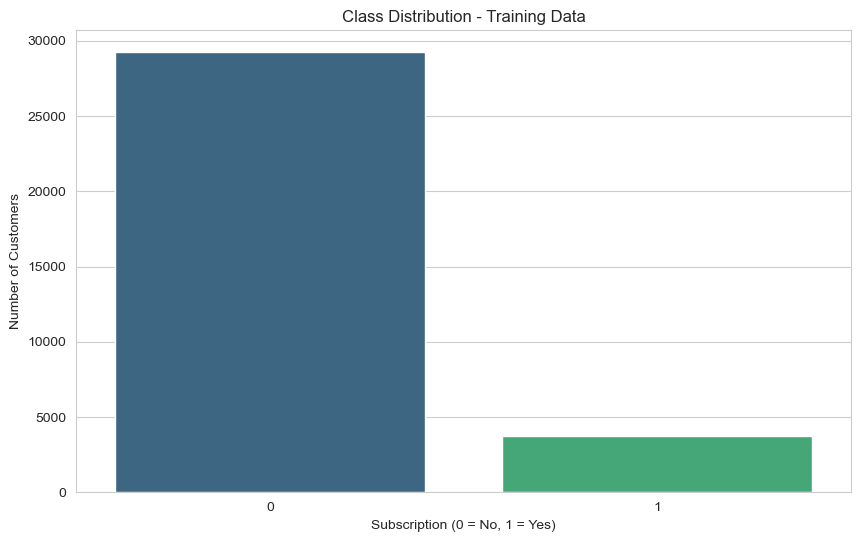

In [93]:
print("Training Target Distribution:")
print(y_train.value_counts())

print("\nPercentage Distribution:")
print(y_train.value_counts(normalize=True) * 100)

sns.countplot(x=y_train, hue=y_train, palette='viridis', legend=False)
plt.title("Class Distribution - Training Data")
plt.xlabel("Subscription (0 = No, 1 = Yes)")
plt.ylabel("Number of Customers")
plt.show()

In [95]:
models = {
    "Logistic Regression": LogisticRegression(
        max_iter=1000,
        class_weight='balanced',
        random_state=42
    ),

    "Decision Tree": DecisionTreeClassifier(
        class_weight='balanced',
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        class_weight='balanced',
        random_state=42,
        n_jobs=-1
    ),

    "Gradient Boosting": GradientBoostingClassifier(
        n_estimators=100,
        learning_rate=0.1,
        random_state=42
    )
}

print("Four machine learning models initialized successfully!")

Four machine learning models initialized successfully!


In [97]:
trained_models = {}

for name, model in models.items():

    print(f"Training {name}...")

    model.fit(X_train_processed, y_train)

    trained_models[name] = model

    print(f"{name} trained successfully!\n")

print("All models trained successfully!")

Training Logistic Regression...
Logistic Regression trained successfully!

Training Decision Tree...
Decision Tree trained successfully!

Training Random Forest...
Random Forest trained successfully!

Training Gradient Boosting...
Gradient Boosting trained successfully!

All models trained successfully!


In [99]:
print("Trained Models:")

for name in trained_models:
    print("-", name)

Trained Models:
- Logistic Regression
- Decision Tree
- Random Forest
- Gradient Boosting


In [101]:
results = []

for name, model in trained_models.items():

    # Predictions
    y_pred = model.predict(X_test_processed)

    # Prediction probabilities
    y_prob = model.predict_proba(X_test_processed)[:, 1]

    # Evaluation metrics
    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(y_test, y_pred, zero_division=0)
    recall = recall_score(y_test, y_pred, zero_division=0)
    f1 = f1_score(y_test, y_pred, zero_division=0)
    roc_auc = roc_auc_score(y_test, y_prob)

    results.append({
        'Model': name,
        'Accuracy': accuracy,
        'Precision': precision,
        'Recall': recall,
        'F1 Score': f1,
        'ROC-AUC': roc_auc
    })

results_df = pd.DataFrame(results)

print("Model Performance Comparison:")
display(results_df.round(4))

Model Performance Comparison:


,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Logistic Regression,0.8350,0.3679,0.6466,0.4689,0.8009
1,Decision Tree,0.8468,0.3216,0.3244,0.3230,0.6192
2,Random Forest,0.8948,0.5659,0.2823,0.3767,0.7823
3,Gradient Boosting,0.9011,0.6728,0.2371,0.3506,0.8091


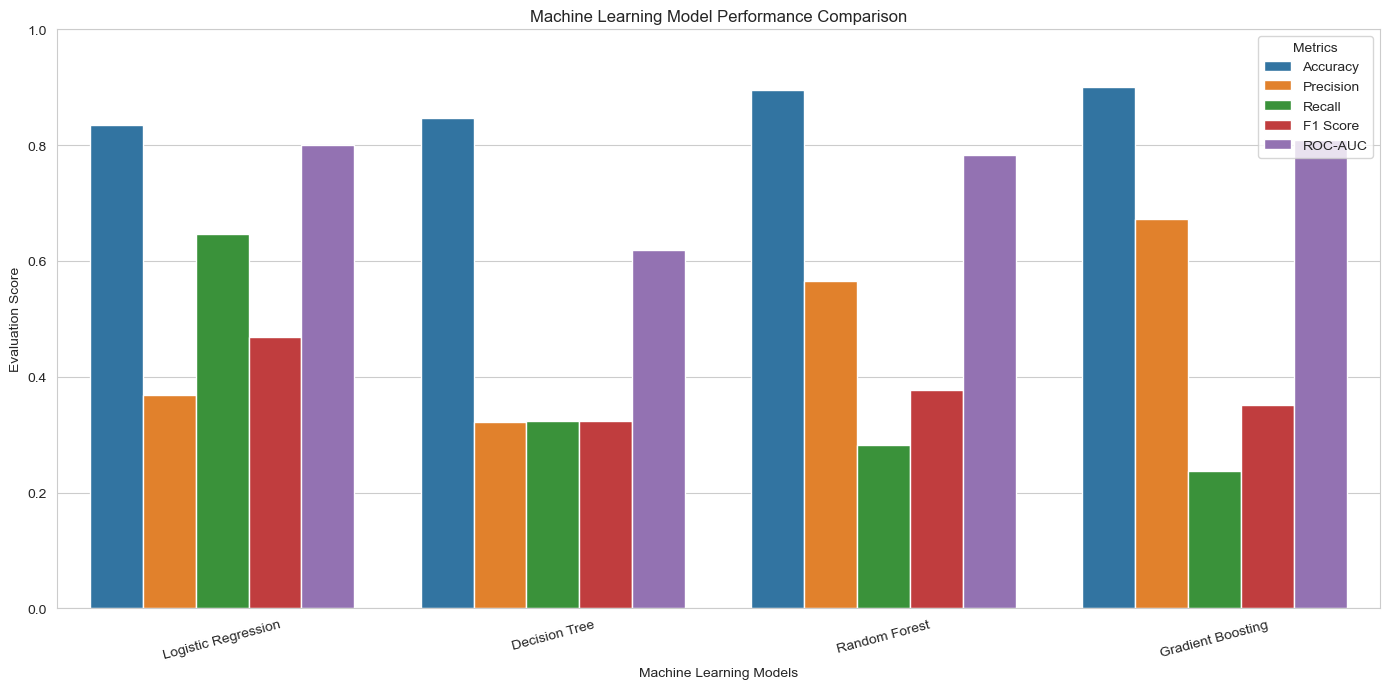

In [103]:
metrics = ['Accuracy', 'Precision', 'Recall', 'F1 Score', 'ROC-AUC']

results_melted = results_df.melt(
    id_vars='Model',
    value_vars=metrics,
    var_name='Metric',
    value_name='Score'
)

plt.figure(figsize=(14, 7))

sns.barplot(
    data=results_melted,
    x='Model',
    y='Score',
    hue='Metric'
)

plt.title('Machine Learning Model Performance Comparison')
plt.xlabel('Machine Learning Models')
plt.ylabel('Evaluation Score')
plt.ylim(0, 1)
plt.xticks(rotation=15)
plt.legend(title='Metrics')
plt.tight_layout()
plt.show()

In [105]:
best_model_name = results_df.loc[
    results_df['F1 Score'].idxmax(),
    'Model'
]

best_model = trained_models[best_model_name]

print("Best Model:", best_model_name)
print(
    "Best F1 Score:",
    round(results_df['F1 Score'].max(), 4)
)

Best Model: Logistic Regression
Best F1 Score: 0.4689


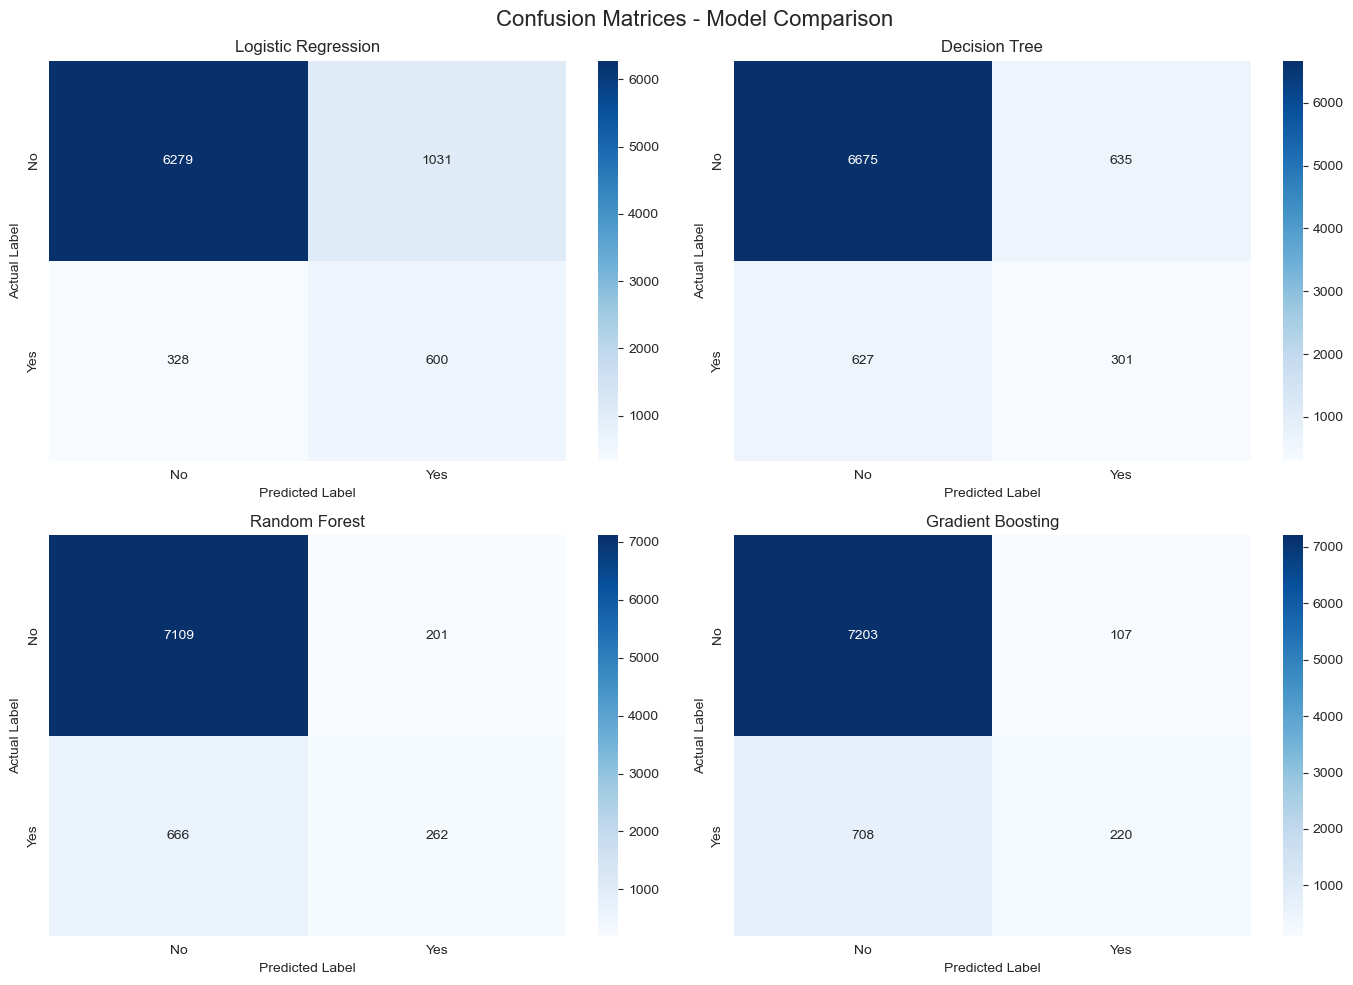

In [107]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

for ax, (name, model) in zip(axes.flatten(), trained_models.items()):

    y_pred = model.predict(X_test_processed)

    cm = confusion_matrix(y_test, y_pred)

    sns.heatmap(
        cm,
        annot=True,
        fmt='d',
        cmap='Blues',
        ax=ax,
        xticklabels=['No', 'Yes'],
        yticklabels=['No', 'Yes']
    )

    ax.set_title(name)
    ax.set_xlabel('Predicted Label')
    ax.set_ylabel('Actual Label')

plt.suptitle('Confusion Matrices - Model Comparison', fontsize=16)
plt.tight_layout()
plt.show()

In [109]:
best_predictions = best_model.predict(X_test_processed)

print("Best Model:", best_model_name)

print("\nClassification Report:\n")

print(
    classification_report(
        y_test,
        best_predictions,
        target_names=['No Subscription', 'Subscription']
    )
)

Best Model: Logistic Regression

Classification Report:

                 precision    recall  f1-score   support

No Subscription       0.95      0.86      0.90      7310
   Subscription       0.37      0.65      0.47       928

       accuracy                           0.84      8238
      macro avg       0.66      0.75      0.69      8238
   weighted avg       0.88      0.84      0.85      8238



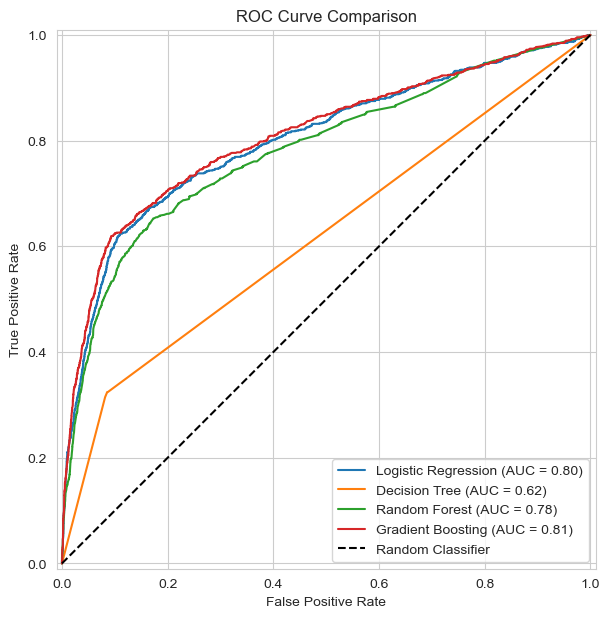

In [111]:
plt.figure(figsize=(10, 7))

for name, model in trained_models.items():

    y_prob = model.predict_proba(X_test_processed)[:, 1]

    RocCurveDisplay.from_predictions(
        y_test,
        y_prob,
        name=name,
        ax=plt.gca()
    )

plt.plot([0, 1], [0, 1], 'k--', label='Random Classifier')

plt.title('ROC Curve Comparison')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.legend()
plt.show()

In [113]:
# Get transformed feature names
feature_names = preprocessor.get_feature_names_out()

print("Total Features:", len(feature_names))
print("\nSample Feature Names:")
print(feature_names[:20])

Total Features: 62

Sample Feature Names:
['num__age' 'num__campaign' 'num__pdays' 'num__previous'
 'num__emp.var.rate' 'num__cons.price.idx' 'num__cons.conf.idx'
 'num__euribor3m' 'num__nr.employed' 'cat__job_admin.'
 'cat__job_blue-collar' 'cat__job_entrepreneur' 'cat__job_housemaid'
 'cat__job_management' 'cat__job_retired' 'cat__job_self-employed'
 'cat__job_services' 'cat__job_student' 'cat__job_technician'
 'cat__job_unemployed']


In [115]:
# Extract the trained Random Forest model
rf_model = trained_models["Random Forest"]

# Extract feature importance
feature_importance = pd.DataFrame({
    'Feature': feature_names,
    'Importance': rf_model.feature_importances_
})

# Sort by importance
feature_importance = feature_importance.sort_values(
    by='Importance',
    ascending=False
)

print("Top 15 Important Features:")
display(feature_importance.head(15))

Top 15 Important Features:


,Feature,Importance
0,num__age,0.135034
7,num__euribor3m,0.123606
1,num__campaign,0.077116
8,num__nr.employed,0.057941
4,num__emp.var.rate,0.047114
6,num__cons.conf.idx,0.030410
5,num__cons.price.idx,0.021628
2,num__pdays,0.021614
38,cat__housing_yes,0.018799
36,cat__housing_no,0.018658


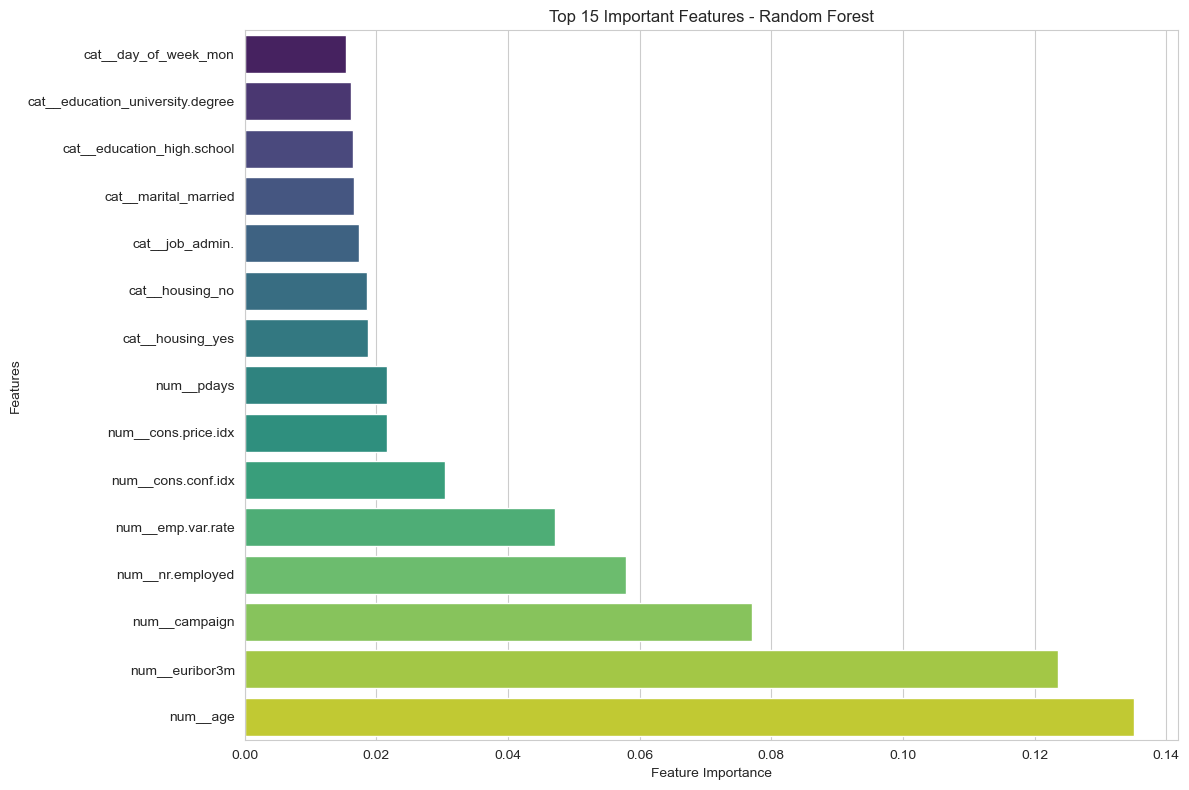

In [117]:
top_features = feature_importance.head(15).sort_values(
    by='Importance',
    ascending=True
)

plt.figure(figsize=(12, 8))

sns.barplot(
    data=top_features,
    x='Importance',
    y='Feature',
    hue='Feature',
    palette='viridis',
    legend=False
)

plt.title('Top 15 Important Features - Random Forest')
plt.xlabel('Feature Importance')
plt.ylabel('Features')
plt.tight_layout()
plt.show()

In [119]:
from sklearn.model_selection import GridSearchCV

print("GridSearchCV imported successfully!")

GridSearchCV imported successfully!


In [121]:
param_grid = {
    'n_estimators': [100, 200],
    'max_depth': [10, 20, None],
    'min_samples_split': [2, 5],
    'min_samples_leaf': [1, 2],
    'max_features': ['sqrt', 'log2']
}

print("Hyperparameter grid created!")

Hyperparameter grid created!


In [123]:
rf_tuning = RandomForestClassifier(
    class_weight='balanced',
    random_state=42,
    n_jobs=-1
)

grid_search = GridSearchCV(
    estimator=rf_tuning,
    param_grid=param_grid,
    cv=3,
    scoring='f1',
    n_jobs=-1,
    verbose=1
)

grid_search.fit(X_train_processed, y_train)

print("Hyperparameter tuning completed!")

Fitting 3 folds for each of 48 candidates, totalling 144 fits
Hyperparameter tuning completed!


In [125]:
print("Best Parameters:")
print(grid_search.best_params_)

print("\nBest Cross-Validation F1 Score:")
print(round(grid_search.best_score_, 4))

Best Parameters:
{'max_depth': 20, 'max_features': 'log2', 'min_samples_leaf': 2, 'min_samples_split': 2, 'n_estimators': 200}

Best Cross-Validation F1 Score:
0.4894


In [127]:
best_rf_model = grid_search.best_estimator_

optimized_predictions = best_rf_model.predict(X_test_processed)

print("Optimized Random Forest Performance:\n")

print(
    classification_report(
        y_test,
        optimized_predictions,
        target_names=['No Subscription', 'Subscription']
    )
)

print(
    "Optimized F1 Score:",
    round(f1_score(y_test, optimized_predictions), 4)
)

Optimized Random Forest Performance:

                 precision    recall  f1-score   support

No Subscription       0.95      0.92      0.93      7310
   Subscription       0.49      0.58      0.53       928

       accuracy                           0.89      8238
      macro avg       0.72      0.75      0.73      8238
   weighted avg       0.89      0.89      0.89      8238

Optimized F1 Score: 0.5312


In [129]:
# Calculate optimized model metrics
optimized_probabilities = best_rf_model.predict_proba(X_test_processed)[:, 1]

optimized_results = {
    'Model': 'Optimized Random Forest',
    'Accuracy': accuracy_score(y_test, optimized_predictions),
    'Precision': precision_score(y_test, optimized_predictions, zero_division=0),
    'Recall': recall_score(y_test, optimized_predictions, zero_division=0),
    'F1 Score': f1_score(y_test, optimized_predictions, zero_division=0),
    'ROC-AUC': roc_auc_score(y_test, optimized_probabilities)
}

# Add optimized model to comparison
final_results_df = pd.concat([
    results_df,
    pd.DataFrame([optimized_results])
], ignore_index=True)

display(final_results_df.round(4))

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Logistic Regression,0.8350,0.3679,0.6466,0.4689,0.8009
1,Decision Tree,0.8468,0.3216,0.3244,0.3230,0.6192
2,Random Forest,0.8948,0.5659,0.2823,0.3767,0.7823
3,Gradient Boosting,0.9011,0.6728,0.2371,0.3506,0.8091
4,Optimized Random Forest,0.8852,0.4917,0.5776,0.5312,0.8084


In [131]:
best_final_model_name = final_results_df.loc[
    final_results_df['F1 Score'].idxmax(),
    'Model'
]

if best_final_model_name == 'Optimized Random Forest':
    final_model = best_rf_model
else:
    final_model = trained_models[best_final_model_name]

print("Selected Final Model:", best_final_model_name)

print(
    "Final F1 Score:",
    round(final_results_df['F1 Score'].max(), 4)
)

Selected Final Model: Optimized Random Forest
Final F1 Score: 0.5312


In [133]:
import joblib
import os

# Create models directory
os.makedirs('models', exist_ok=True)

# Save model
joblib.dump(
    final_model,
    'models/bank_marketing_model.pkl'
)

# Save preprocessing pipeline
joblib.dump(
    preprocessor,
    'models/bank_marketing_preprocessor.pkl'
)

print("Final model and preprocessing pipeline saved successfully!")

Final model and preprocessing pipeline saved successfully!


In [135]:
print("Saved Model Files:")

print(os.listdir('models'))

Saved Model Files:
['bank_marketing_model.pkl', 'bank_marketing_preprocessor.pkl']


In [137]:
import joblib

# Load saved model
loaded_model = joblib.load('models/bank_marketing_model.pkl')

# Load preprocessing pipeline
loaded_preprocessor = joblib.load(
    'models/bank_marketing_preprocessor.pkl'
)

print("Model loaded successfully!")
print("Preprocessor loaded successfully!")

Model loaded successfully!
Preprocessor loaded successfully!


In [139]:
# Sample customer 1
customer_1 = {
    'age': 35,
    'job': 'admin.',
    'marital': 'married',
    'education': 'university.degree',
    'default': 'no',
    'housing': 'yes',
    'loan': 'no',
    'contact': 'cellular',
    'month': 'may',
    'day_of_week': 'mon',
    'campaign': 1,
    'pdays': 999,
    'previous': 0,
    'poutcome': 'nonexistent',
    'emp.var.rate': 1.1,
    'cons.price.idx': 93.994,
    'cons.conf.idx': -36.4,
    'euribor3m': 4.857,
    'nr.employed': 5191.0
}

# Sample customer 2
customer_2 = {
    'age': 52,
    'job': 'retired',
    'marital': 'married',
    'education': 'basic.9y',
    'default': 'no',
    'housing': 'no',
    'loan': 'no',
    'contact': 'telephone',
    'month': 'nov',
    'day_of_week': 'wed',
    'campaign': 2,
    'pdays': 6,
    'previous': 1,
    'poutcome': 'success',
    'emp.var.rate': -1.1,
    'cons.price.idx': 94.767,
    'cons.conf.idx': -50.8,
    'euribor3m': 1.028,
    'nr.employed': 4963.6
}

new_customers = pd.DataFrame([
    customer_1,
    customer_2
])

display(new_customers)

,age,job,marital,education,default,housing,loan,contact,month,day_of_week,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed
0,35,admin.,married,university.degree,no,yes,no,cellular,may,mon,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0
1,52,retired,married,basic.9y,no,no,no,telephone,nov,wed,2,6,1,success,-1.1,94.767,-50.8,1.028,4963.6


In [141]:
new_customers_processed = loaded_preprocessor.transform(
    new_customers
)

print("New customer data preprocessed successfully!")
print("Processed Shape:", new_customers_processed.shape)

New customer data preprocessed successfully!
Processed Shape: (2, 62)


In [143]:
predictions = loaded_model.predict(new_customers_processed)

probabilities = loaded_model.predict_proba(
    new_customers_processed
)[:, 1]

prediction_results = new_customers.copy()

prediction_results['Predicted Subscription'] = [
    'Yes' if prediction == 1 else 'No'
    for prediction in predictions
]

prediction_results['Subscription Probability (%)'] = (
    probabilities * 100
).round(2)

display(
    prediction_results[
        ['age', 'job', 'marital',
         'Predicted Subscription',
         'Subscription Probability (%)']
    ]
)

,age,job,marital,Predicted Subscription,Subscription Probability (%)
0,35,admin.,married,No,23.05
1,52,retired,married,Yes,78.94


In [145]:
pip install streamlit

Note: you may need to restart the kernel to use updated packages.


In [147]:
import os
print(os.getcwd())

C:\Users\lubna shireen\Bank Marketing Response Prediction


In [149]:

import json

# Get the selected final model's evaluation results
selected_metrics = final_results_df[
    final_results_df['Model'] == best_final_model_name
].iloc[0]

# Store performance metrics
model_metrics = {
    "model_name": best_final_model_name,
    "accuracy": float(selected_metrics['Accuracy']),
    "precision": float(selected_metrics['Precision']),
    "recall": float(selected_metrics['Recall']),
    "f1_score": float(selected_metrics['F1 Score']),
    "roc_auc": float(selected_metrics['ROC-AUC'])
}

# Save metrics as JSON
with open('models/model_metrics.json', 'w') as file:
    json.dump(model_metrics, file, indent=4)

print("Model evaluation metrics saved successfully!")
print(model_metrics)


Model evaluation metrics saved successfully!
{'model_name': 'Optimized Random Forest', 'accuracy': 0.8851663025006069, 'precision': 0.4917431192660551, 'recall': 0.5775862068965517, 'f1_score': 0.5312190287413281, 'roc_auc': 0.8084428363366196}
